# Why domain-adversarial training can *hide* the domain instead of removing it

**A self-contained toy model.** Everything below is built from scratch on two-dimensional
synthetic data and runs on a CPU in a few minutes. No prior reading is assumed: every symbol
is defined where it first appears, every architecture is drawn, every claim is measured.

### The question

We want a representation $z$ of the data in which

* the **class** (signal vs background) is still decidable, and
* the **domain** (which dataset an event came from) is *not* decidable.

The standard recipe is *domain-adversarial training*: attach a second network — a
**discriminator** — that tries to guess the domain from $z$, and train the encoder to make it
fail. This notebook shows, on a model small enough to inspect by eye, that the encoder has two
very different ways to satisfy that request:

| way | what happens to the domain information | what it costs the class |
|---|---|---|
| **remove it** | the two domains really become one cloud | the representation has to change a lot |
| **hide it** | the information survives, but moves into directions the *current* discriminator does not read | almost nothing |

Only the first one is domain invariance. Distinguishing them is the whole point.

### Roadmap

1. the data and the two labels (§1)
2. the model, drawn and written out (§2)
3. why a discriminator reads **one direction** only (§3)
4. what we measure, and why a *freshly refitted* reader is the honest meter (§4)
5. **Case A** — linear encoder: you can literally watch the feature space rotate (§5)
6. **Case B** — nonlinear encoder: a stably blind discriminator with the domain still present (§6)
7. the decisive test and the practical checklist (§7–§8)

### Notation used throughout

| symbol | meaning |
|---|---|
| $x \in \mathbb{R}^2$ | one sample; in a real experiment this would be an event's features |
| $y \in \{0,1\}$ | **class** label: $0$ = background, $1$ = signal (known only for the source) |
| $d \in \{0,1\}$ | **domain** label: $0$ = source, $1$ = target (known for everything) |
| $W$ | the **encoder**: a $2\times 2$ matrix, $z = Wx$ (Case B: a small MLP) |
| $z \in \mathbb{R}^2$ | the **representation** (feature vector) — the object everything acts on |
| $v$ | the **classifier**: a linear readout, class logit $= v^\top z$ |
| $w,\;b$ | the **discriminator**: domain logit $= w^\top z + b$ |
| $\lambda$ | how strongly the encoder is pushed to fool the discriminator |
| $a$ | the **domain shift**, $a = \mathbb{E}[x\,|\,d{=}1] - \mathbb{E}[x\,|\,d{=}0]$ |

## §1 The data: one class axis, one domain axis

We build a two-dimensional dataset with a deliberately clean structure. Each sample is a point
$x = (x_1, x_2)$ generated as

$$
x \;=\; \underbrace{c_y \cdot e_1}_{\text{class position}} \;+\; \underbrace{d \cdot a}_{\text{domain shift}} \;+\; \underbrace{\varepsilon}_{\text{noise}},\qquad
\varepsilon \sim \mathcal{N}(0, \sigma^2 I),
$$

with $e_1 = (1,0)$, $c_0 = -1.5$, $c_1 = +1.5$ and the domain shift $a = (0,\,1.6)$ along the
*second* axis.

In words: the two classes sit on the horizontal axis, and the target domain is the source
domain translated vertically. The class direction and the domain direction are **orthogonal**,
which makes this the most favourable possible situation for hiding — an encoder can move the
domain around without touching the class structure.

* **source** (domain $d=0$): both classes present, both labelled. This plays the role of
  simulated data with known truth.
* **target** (domain $d=1$): only *background-like* events ($y=0$), shifted by $a$, and
  **unlabelled** — this plays the role of real data.

The class labels are known for the source and unknown for the target; the domain labels are
known for everything. That asymmetry is what domain-adversarial training exploits.

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

torch.manual_seed(0)
np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "font.size": 10})

# ---- data-generating constants (all defined here, used everywhere below) ----
C_CLASS = 1.5          # c_0 = -C_CLASS, c_1 = +C_CLASS: where the two classes sit
SHIFT   = 1.6          # |a|: how far the target domain is displaced
SIGMA   = 0.5          # noise standard deviation
N       = 4096         # samples per cloud

E1 = np.array([1.0, 0.0])            # class axis
E2 = np.array([0.0, 1.0])            # domain axis
A_VEC = torch.tensor([0.0, SHIFT])   # the domain shift vector a


def make_data(seed):
    # returns (source class 0, source class 1, target) as float32 tensors
    g = np.random.default_rng(seed)
    T = lambda arr: torch.tensor(arr, dtype=torch.float32)
    src0 = T(g.normal(0, SIGMA, (N, 2)) - C_CLASS * E1)              # source, y = 0
    src1 = T(g.normal(0, SIGMA, (N, 2)) + C_CLASS * E1)              # source, y = 1
    tgt = T(g.normal(0, SIGMA, (N, 2)) - C_CLASS * E1 + SHIFT * E2)  # target (unlabelled)
    return src0, src1, tgt


s0, s1, tgt = make_data(1)      # training clouds
h0, h1, ht = make_data(2)       # held-out clouds: every number below is measured on these

print("source class 0 mean:", s0.mean(0).numpy().round(2))
print("source class 1 mean:", s1.mean(0).numpy().round(2))
print("target          mean:", tgt.mean(0).numpy().round(2))
print("domain shift a =", A_VEC.numpy())

source class 0 mean: [-1.5  -0.01]
source class 1 mean: [ 1.5  -0.01]
target          mean: [-1.5   1.59]
domain shift a = [0.  1.6]


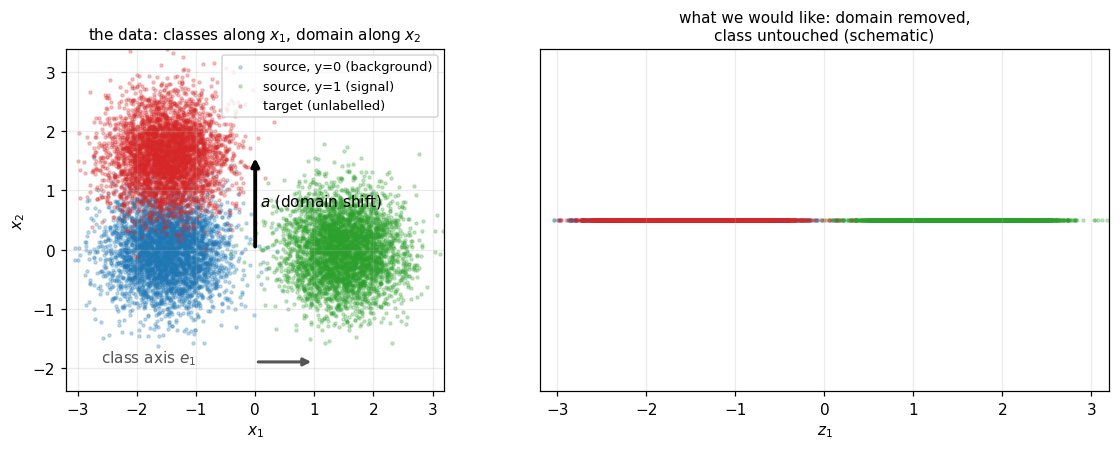

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

ax = axes[0]
ax.scatter(s0[:, 0], s0[:, 1], s=4, alpha=0.25, color="#1f77b4", label="source, y=0 (background)")
ax.scatter(s1[:, 0], s1[:, 1], s=4, alpha=0.25, color="#2ca02c", label="source, y=1 (signal)")
ax.scatter(tgt[:, 0], tgt[:, 1], s=4, alpha=0.25, color="#d62728", label="target (unlabelled)")
ax.annotate("", xy=(0, 1.6), xytext=(0, 0),
            arrowprops=dict(arrowstyle="-|>", lw=2.5, color="black"))
ax.text(0.08, 0.75, "$a$ (domain shift)", fontsize=10)
ax.text(-2.6, -1.9, "class axis $e_1$", fontsize=10, color="#555")
ax.annotate("", xy=(1.0, -1.9), xytext=(0.0, -1.9),
            arrowprops=dict(arrowstyle="-|>", lw=2, color="#555"))
ax.set_xlim(-3.2, 3.2); ax.set_ylim(-2.4, 3.4); ax.set_aspect("equal")
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.legend(fontsize=8.5, loc="upper right")
ax.set_title("the data: classes along $x_1$, domain along $x_2$", fontsize=10)

# what the *ideal* representation would look like: class visible, domain gone
ax = axes[1]
ax.scatter(s0[:, 0], s0[:, 1] * 0, s=4, alpha=0.25, color="#1f77b4")
ax.scatter(s1[:, 0], s1[:, 1] * 0, s=4, alpha=0.25, color="#2ca02c")
ax.scatter(tgt[:, 0], tgt[:, 1] * 0, s=4, alpha=0.25, color="#d62728")
ax.set_xlim(-3.2, 3.2); ax.set_ylim(-0.6, 0.6)
ax.set_xlabel("$z_1$"); ax.set_yticks([])
ax.set_title("what we would like: domain removed,\nclass untouched (schematic)", fontsize=10)
plt.tight_layout(); plt.show()

## §2 The model

We now define the network. There are exactly two ingredients: an **encoder** that produces the
representation, and two **heads** that read it. (A *head* is just a small function attached on
top of a representation; here both heads are single linear layers.)

### The forward pass

$$
z = W x, \qquad
\text{class logit} \;=\; v^\top z, \qquad
\text{domain logit} \;=\; w^\top z + b .
$$

### The losses

The classifier is trained on the **source** only (the target has no class labels):

$$
L_{\text{cls}}(W, v) \;=\; \frac{1}{|S|}\sum_{x \in S}
  \mathrm{BCE}\!\left(v^\top W x,\; y(x)\right),
\qquad
\mathrm{BCE}(u, y) = -\big[y\log\sigma(u) + (1-y)\log(1-\sigma(u))\big],
$$

where $S$ is a batch of source samples, $\sigma$ is the sigmoid and $y(x)$ is the class label.

The discriminator is trained on **both** domains. It must output $0$ on source samples and $1$ on
target samples:

$$
L_{\text{dom}}(W, w, b) \;=\; \frac{1}{2}\Big[
  \underbrace{\frac{1}{|S|}\sum_{x\in S}\mathrm{BCE}\!\left(w^\top W x + b,\; 0\right)}_{\text{source part}}
  \;+\;
  \underbrace{\frac{1}{|T|}\sum_{x\in T}\mathrm{BCE}\!\left(w^\top W x + b,\; 1\right)}_{\text{target part}}
\Big].
$$

### The game

$$
\min_{W,\,v}\;\Big[\,L_{\text{cls}} \;-\; \lambda\, L_{\text{dom}}\,\Big]
\qquad\text{and}\qquad
\min_{w,\,b}\; L_{\text{dom}} .
$$

Read it as a contest over the same $z$:

* the discriminator $w$ **minimises** $L_{\text{dom}}$ — it wants to read the domain correctly;
* the encoder $W$ **maximises** $L_{\text{dom}}$ (that is what the minus sign does) — it wants the
  discriminator to be wrong — while still minimising $L_{\text{cls}}$.

$\lambda$ sets how much the encoder cares about fooling the discriminator relative to doing its
class job. In the code below $\lambda = 1$; in real training it is usually ramped up slowly.

### How it is implemented: the gradient reversal layer

Both updates come from a **single** backward pass through a *gradient reversal* (GRL) layer
placed between $z$ and the discriminator:

$$
\text{forward: } z \mapsto z, \qquad
\text{backward: } \nabla \mapsto -\lambda\,\nabla .
$$

Because this layer does nothing in the forward direction, the discriminator's own parameters
still receive $+\nabla L_{\text{dom}}$ (it learns normally), while everything *below* the layer —
the encoder — receives $-\lambda \nabla L_{\text{dom}}$, i.e. ascends the domain loss. One
`.backward()` call, two opposite signs. That is the whole trick of the original DANN paper.

The diagram below draws the two cases we will study.

Case A architecture — the encoder is ONE linear layer (a 2x2 matrix):


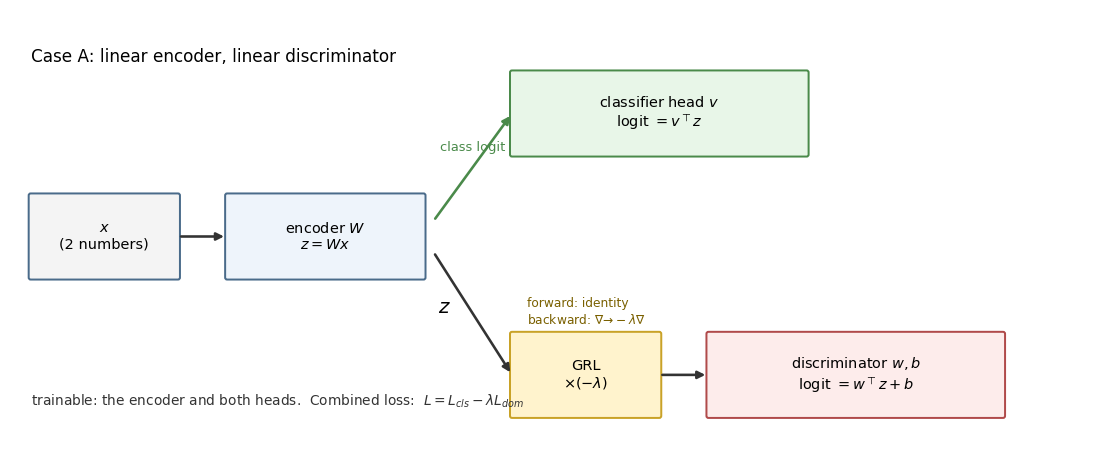

Case B architecture — the encoder is a small MLP with one hidden layer of 16 units:


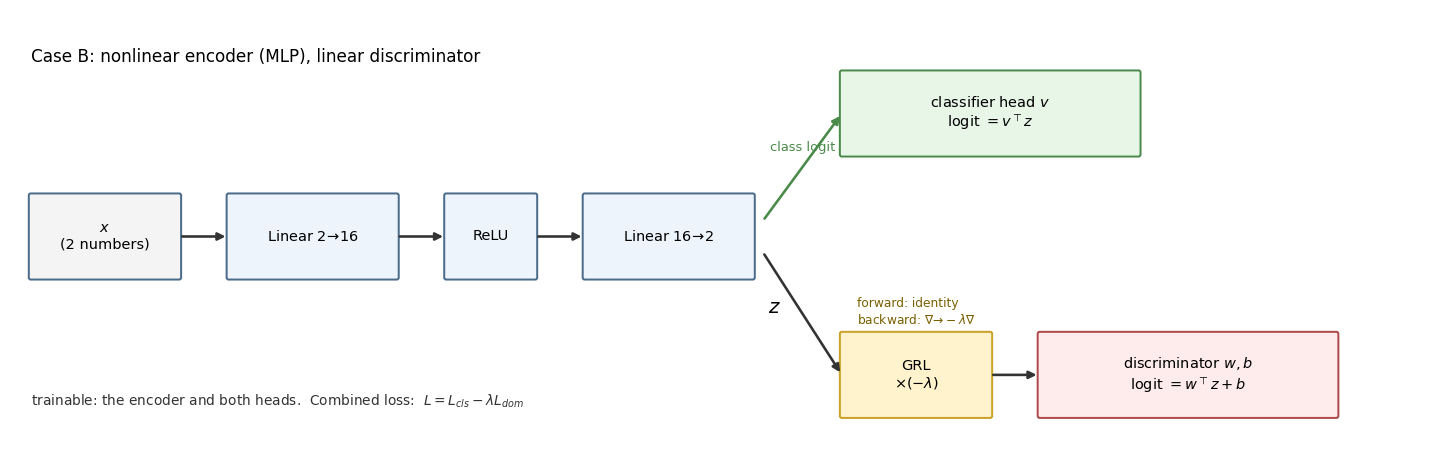

In [3]:
# ---- drawing helpers (used for both architecture diagrams) ----
def box(ax, x, y, w, h, text, fc="#eef4fb", ec="#4a6b8a", fs=9.5):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02", fc=fc, ec=ec, lw=1.3))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs)


def arrow(ax, p, q, text="", color="#333333", lw=1.7, ls="-"):
    ax.annotate("", xy=q, xytext=p,
                arrowprops=dict(arrowstyle="-|>", color=color, lw=lw, ls=ls))
    if text:
        ax.text((p[0] + q[0]) / 2, (p[1] + q[1]) / 2 + 0.16, text, ha="center",
                fontsize=8.5, color=color)


def architecture(sizes, title):
    # sizes: list of (box label, width) along the main chain; plus the two heads
    chain = 2.2 + sum(w + 0.5 for _, w in sizes)     # x position where z lives
    x_max = chain + 6.4                              # room for both heads
    fig, ax = plt.subplots(figsize=(x_max * 0.92, 4.4))
    ax.set_xlim(0, x_max); ax.set_ylim(0, 4.4); ax.axis("off")
    box(ax, 0.2, 1.8, 1.5, 0.8, "$x$\n(2 numbers)", fc="#f4f4f4")
    x = 2.2
    for label, w in sizes:
        box(ax, x, 1.8, w, 0.8, label)
        arrow(ax, (x - 0.5, 2.2), (x, 2.2))
        x += w + 0.5
    zx = x - 0.5                      # right edge of the encoder chain = where z lives
    ax.text(zx + 0.15, 1.45, "$z$", fontsize=13)
    box(ax, zx + 0.9, 3.0, 3.0, 0.8, "classifier head $v$\nlogit $= v^\\top z$", fc="#e8f6e8",
        ec="#4a8a4a")
    arrow(ax, (zx + 0.1, 2.35), (zx + 0.9, 3.4), "class logit", color="#4a8a4a")
    box(ax, zx + 0.9, 0.45, 1.5, 0.8, "GRL\n$\\times(-\\lambda)$", fc="#fff3cd", ec="#c9a227")
    box(ax, zx + 2.9, 0.45, 3.0, 0.8, "discriminator $w,b$\nlogit $= w^\\top z + b$",
        fc="#fdeceb", ec="#b04a4a")
    arrow(ax, (zx + 0.1, 2.05), (zx + 0.9, 0.85), "", color="#333333")
    arrow(ax, (zx + 2.4, 0.85), (zx + 2.9, 0.85), "", color="#333333")
    ax.text(zx + 1.05, 1.35, "forward: identity\nbackward: $\\nabla\\!\\to\\!-\\lambda\\nabla$",
            fontsize=8, color="#7a6000")
    ax.text(0.2, 3.9, title, fontsize=11)
    ax.text(0.2, 0.55,
            "trainable: the encoder and both heads.  Combined loss:  "
            "$L = L_{cls} - \\lambda L_{dom}$",
            fontsize=9, color="#333333")
    plt.tight_layout(); plt.show()


print("Case A architecture — the encoder is ONE linear layer (a 2x2 matrix):")
architecture([("encoder $W$\n$z = Wx$", 2.0)], "Case A: linear encoder, linear discriminator")

print("Case B architecture — the encoder is a small MLP with one hidden layer of 16 units:")
architecture([("Linear $2\\!\\to\\!16$", 1.7), ("ReLU", 0.9), ("Linear $16\\!\\to\\!2$", 1.7)],
             "Case B: nonlinear encoder (MLP), linear discriminator")

## §3 Why a discriminator reads only one direction

This section is the heart of the matter, and it is three lines of calculus.

The discriminator sees the representation $z$ only through the scalar $u = w^\top z + b$. Write
the per-sample domain loss as $\ell(u, d) = \mathrm{BCE}(u, d)$. Two facts:

1. the derivative of the logistic loss with respect to the logit is the prediction error.
   With $\sigma' = \sigma(1-\sigma)$,

$$
\frac{\partial}{\partial u}\ln\sigma(u) = \frac{\sigma'}{\sigma} = 1-\sigma,
\qquad
\frac{\partial}{\partial u}\ln\big(1-\sigma(u)\big) = \frac{-\sigma'}{1-\sigma} = -\sigma,
$$

$$
\Longrightarrow\qquad
\frac{\partial \ell}{\partial u}
= -\big[d\,(1-\sigma) - (1-d)\,\sigma\big]
= \sigma(u) - d ;
$$

2. the gradient of the logit with respect to the features is the readout vector,
   $\dfrac{\partial u}{\partial z} = w$ (because $u = w^\top z + b$).

Chaining them,

$$
\boxed{\;\frac{\partial \ell}{\partial z} \;=\; \big(\sigma(w^\top z + b) - d\big)\cdot w\;}
$$

**Every sample pushes the representation along the *same* vector $w$** — provided the
discriminator's *last* layer is linear, which is the usual construction (the multi-layer case is
handled by the warning below). The scalar in front depends on the sample (it is the
discriminator's error on that sample), but the direction is one and the same for the whole batch.

Consequences that we will see on the plots:

* what follows **directly** from the gradient (worked out in §3.1 below) is that the encoder
  *contracts the domain difference along $w$* — it pulls the two clouds together **in the
  direction the discriminator is looking**, and leaves the orthogonal component untouched;
* in two dimensions, contracting one component while keeping the other is exactly a **rotation**
  of the domain-difference vector towards $w^{\perp}$. The rotation is not an extra mechanism —
  it is what the one-step formula looks like after a few iterations;
* directions orthogonal to $w$ are, for this discriminator, *invisible*: any amount of domain
  signal stored there costs the domain loss nothing.

**A warning about "one direction".** The statement above is exact for a discriminator whose last
layer is linear — the usual case, and the one drawn in §2. If the whole discriminator is a
multi-layer network, $D(z) = \sigma(f(z))$, the chain rule gives

$$
\frac{\partial \ell}{\partial z} \;=\; \big(\sigma(f(z)) - d\big)\cdot \nabla_z f(z),
$$

so the *magnitude* is still the critic's error, but the *direction* $\nabla_z f(z)$ is now local:
one direction **per sample**, not one for the whole batch. What survives is that each sample
contributes a rank-one push, and that the equilibrium argument of §8 never used linearity. What
changes is the shape of the blind set: for a linear reader it is the hyperplane $w^{\perp}$, while
for a network it is the set of points where the critic's score is locally flat,
$\{\nabla_z f(z)\approx 0\}$ — a curved set, generically much thinner. Fooling a *network* critic
is therefore harder than the clean rotation shown below; and this is the situation in real
experiments, where the discriminator is a multi-layer network.

### §3.1 What exactly one gradient step does

For a linear encoder the domain gradient is a sum of outer products (each sample pushes the
representation along $w$ with a weight equal to its own error):

$$
\frac{\partial L_{\text{dom}}}{\partial W}
= \sum_i \big(\sigma(w^\top z_i + b) - d_i\big)\,w\,x_i^\top,
\qquad\text{so}\qquad
W \;\leftarrow\; W + \eta\lambda \sum_i (\sigma_i - d_i)\,w\,x_i^\top .
$$

Track the **domain-difference vector** $Wa$ (how far apart the two clouds are in feature space):

$$
\delta(Wa) \;=\; \delta W\,a \;=\; \eta\lambda \sum_i (\sigma_i - d_i)\,(x_i^\top a)\,w .
$$

In our data the class axis is orthogonal to the shift $a$, so $x_i^\top a \approx 0$ for source
samples and $\approx \|a\|^2$ for target samples; and for target samples $(\sigma_i - d_i) =
-(1-\sigma_i)$. Hence

$$
\delta(Wa) \;\approx\; -\,\eta\lambda\,\|a\|^2\,\big(1-\bar\sigma_{\text{tgt}}\big)\,w .
$$

The component of the domain difference **along $w$ shrinks** (by an amount proportional to how
confident the critic is), while the component orthogonal to $w$ is untouched. Iterating this in
two dimensions rotates $Wa$ towards $w^{\perp}$: the feature space rotates, and the class is
unaffected because the map stays invertible and the class axis is a different direction. The cell
below checks this formula against autograd.

Call $w^{\perp}$ the **blind direction**: the set of directions orthogonal to $w$ (in 2D, a line
through the origin). It is the place where a domain signal can wait.

In particular, if the domain difference can be described by a vector $a$ in the input space and
the encoder is linear, $z = Wx$, then hiding the domain from the current discriminator requires
only

$$
\underbrace{w^\top W a = 0}_{\text{one scalar equation}}
\qquad\text{while}\qquad
\underbrace{\|Wa\| \neq 0}_{\text{the signal is still there}} .
$$

One scalar equation is easy to satisfy: for $d$-dimensional features there are $d^2$ entries in
$W$ and only one constraint, so the solution set is a hyperplane. In 2D the encoder has to rotate
by the right angle; in 128 dimensions it has a lot of room. And note what the second condition
says: the domain signal does not have to disappear — it only has to become invisible *to this
particular reader*.

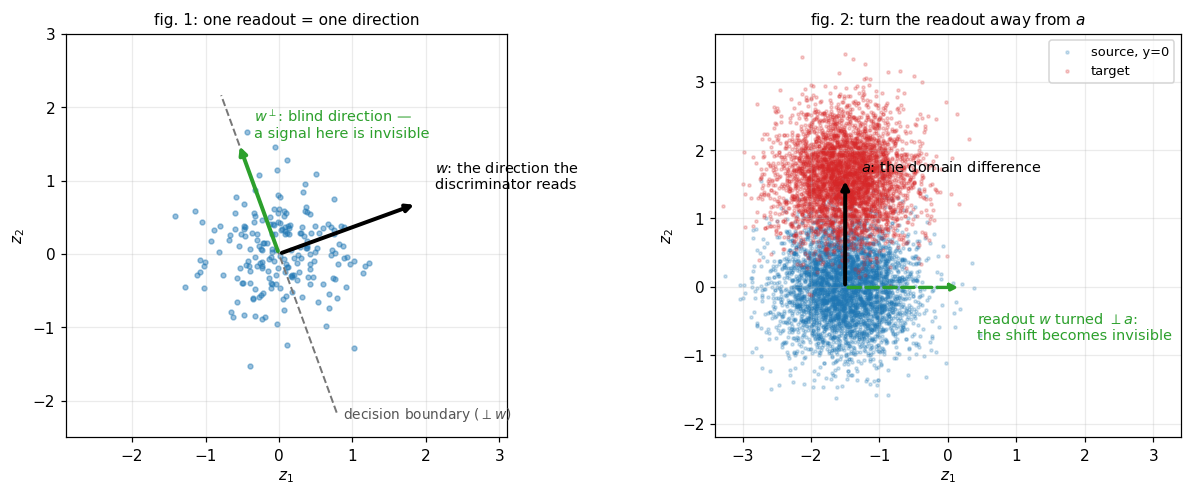

In [4]:
# Picture of the readout geometry: what the discriminator sees, and what it does not.
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))

ax = axes[0]
rng = np.random.default_rng(3)
cloud = rng.normal(0, 0.5, (200, 2))
ax.scatter(cloud[:, 0], cloud[:, 1], s=10, color="#1f77b4", alpha=0.45)
th = np.deg2rad(20)
w_dir = np.array([np.cos(th), np.sin(th)])
perp = np.array([-w_dir[1], w_dir[0]])
ax.annotate("", xy=2.0 * w_dir, xytext=(0, 0),
            arrowprops=dict(arrowstyle="-|>", lw=2.6, color="black"))
ax.annotate("$w$: the direction the\ndiscriminator reads", xy=2.0 * w_dir, xytext=(12, 10),
            textcoords="offset points", fontsize=9.5)
ax.plot(*np.outer(np.array([-2.3, 2.3]), perp).T, ls="--", color="#777777", lw=1.3)
ax.annotate("decision boundary ($\\perp w$)", xy=-2.3 * perp, xytext=(4, -4),
            textcoords="offset points", fontsize=9, color="#555555", ha="left")
ax.annotate("", xy=1.6 * perp, xytext=(0, 0),
            arrowprops=dict(arrowstyle="-|>", lw=2.6, color="#2ca02c"))
ax.annotate("$w^{\\perp}$: blind direction —\na signal here is invisible",
            xy=1.6 * perp, xytext=(10, 4), textcoords="offset points", fontsize=9.5,
            color="#2ca02c")
ax.set_xlim(-2.9, 3.1); ax.set_ylim(-2.5, 3.0); ax.set_aspect("equal")
ax.set_xlabel("$z_1$"); ax.set_ylabel("$z_2$")
ax.set_title("fig. 1: one readout = one direction", fontsize=10)

ax = axes[1]
ax.scatter(s0[:, 0], s0[:, 1], s=4, alpha=0.22, color="#1f77b4", label="source, y=0")
ax.scatter(tgt[:, 0], tgt[:, 1], s=4, alpha=0.22, color="#d62728", label="target")
m_src, m_tgt = s0.mean(0).numpy(), tgt.mean(0).numpy()
ax.annotate("", xy=m_tgt, xytext=m_src,
            arrowprops=dict(arrowstyle="-|>", lw=2.6, color="black"))
ax.annotate("$a$: the domain difference", xy=m_tgt, xytext=(10, 4),
            textcoords="offset points", fontsize=9.5)
ax.annotate("", xy=m_src + np.array([1.7, 0.0]), xytext=m_src,
            arrowprops=dict(arrowstyle="-|>", lw=2.2, color="#2ca02c", ls="--"))
ax.annotate("readout $w$ turned $\\perp a$:\nthe shift becomes invisible",
            xy=m_src + np.array([1.7, 0.0]), xytext=(10, -34), textcoords="offset points",
            fontsize=9.5, color="#2ca02c")
ax.set_xlim(-3.4, 3.4); ax.set_ylim(-2.2, 3.7); ax.set_aspect("equal")
ax.set_xlabel("$z_1$"); ax.set_ylabel("$z_2$")
ax.legend(fontsize=8.5, loc="upper right")
ax.set_title("fig. 2: turn the readout away from $a$", fontsize=10)
plt.tight_layout(); plt.show()

## §4 What we measure, and why the meter must be *fresh*

Three quantities are recorded during training, and they answer three different questions.

| meter | how it is computed | what it answers |
|---|---|---|
| **domain loss** $L_{\text{dom}}$ | the discriminator's own training loss | is the *current* discriminator confused? |
| **discriminator AUC** | the current discriminator's ranking quality on held-out data | same question, but scale-free: $1.0$ = perfect separation, $0.5$ = chance |
| **fresh probe AUC** | a *new* logistic regression fitted on the **frozen** features of held-out data | does the domain information still exist in the representation *at all*? |

*AUC* (area under the ROC curve) is the probability that a randomly chosen target sample gets a
higher domain score than a randomly chosen source sample. It needs no threshold, which is why we
use it instead of accuracy.

The third meter is the important one. The first two are properties of the *current* reader: a
reader that is confused, stale, or simply unauthorised to look in the right direction reports
chance regardless of what the representation contains. A probe is different — it is **refitted
from scratch** on whatever the features currently are, so it cannot be fooled by a stale
direction. If a fresh probe separates the domains, the information is present, full stop.

The price of that honesty: a *linear* probe can only read linear structure. We will meet this
limitation in Case B, where a sufficiently nonlinear encoder hides the domain from linear probes
too — and then only a nonlinear probe reveals that the information is still there.

Finally, we always record the **class accuracy** on held-out source data: hiding that destroys
the class would not be interesting, and we want to see whether it costs anything.

In [5]:
class Rev(torch.autograd.Function):
    # gradient reversal: identity forward, gradient multiplied by -lam backward
    @staticmethod
    def forward(ctx, z, lam):
        ctx.lam = lam
        return z

    @staticmethod
    def backward(ctx, grad):
        return -ctx.lam * grad, None


def fresh_linear_probe_auc(encoder):
    # fit a brand-new logistic regression on frozen held-out features
    with torch.no_grad():
        zs, zt = encoder(torch.cat([h0, h1])), encoder(ht)
    X = np.vstack([zs.numpy(), zt.numpy()])
    y = np.r_[np.zeros(len(zs)), np.ones(len(zt))]
    clf = LogisticRegression(max_iter=2000).fit(X, y)
    return roc_auc_score(y, clf.predict_proba(X)[:, 1])


def fresh_mlp_probe_auc(encoder, steps=800, seed=0):
    # same idea, but the fresh reader is a small MLP: it can read nonlinear structure
    torch.manual_seed(seed)
    with torch.no_grad():
        zs, zt = encoder(torch.cat([h0, h1])), encoder(ht)
    X = torch.cat([zs, zt])
    y = torch.cat([torch.zeros(len(zs)), torch.ones(len(zt))])
    net = nn.Sequential(nn.Linear(X.shape[1], 32), nn.ReLU(), nn.Linear(32, 1))
    opt = torch.optim.Adam(net.parameters(), lr=1e-2)
    for _ in range(steps):
        opt.zero_grad()
        nn.functional.binary_cross_entropy_with_logits(net(X).squeeze(), y).backward()
        opt.step()
    with torch.no_grad():
        return roc_auc_score(y.numpy(), torch.sigmoid(net(X).squeeze()).numpy())


def discriminator_auc(encoder, discriminator):
    with torch.no_grad():
        src_scores = discriminator(encoder(torch.cat([h0, h1]))).squeeze().numpy()
        tgt_scores = discriminator(encoder(ht)).squeeze().numpy()
    return roc_auc_score(np.r_[np.zeros(len(src_scores)), np.ones(len(tgt_scores))],
                         np.r_[src_scores, tgt_scores])


def class_accuracy(encoder, head):
    with torch.no_grad():
        logit = head(encoder(torch.cat([h0, h1]))).squeeze()
    predicted = (logit > 0).float()
    truth = torch.cat([torch.zeros(N), torch.ones(N)])
    return float((predicted == truth).float().mean())


# ---- check the one-step formula of 3.1 against autograd ----
torch.manual_seed(7)
W_chk = (torch.eye(2) + 0.3 * torch.randn(2, 2)).requires_grad_(True)
w_chk = torch.tensor([0.8, 0.6])
b_chk = torch.tensor(0.1)
idx = torch.randint(0, N, (256,))
xs_chk = torch.cat([s0[idx], s1[idx]])
xt_chk = tgt[idx]

zs_chk, zt_chk = xs_chk @ W_chk.T, xt_chk @ W_chk.T
bce = torch.nn.functional.binary_cross_entropy_with_logits
dom_chk = 0.5 * (bce(zs_chk @ w_chk + b_chk, torch.zeros(len(zs_chk)), reduction="mean")
                 + bce(zt_chk @ w_chk + b_chk, torch.ones(len(zt_chk)), reduction="mean"))
grad_W = torch.autograd.grad(dom_chk, W_chk)[0]          # this is dL_dom/dW, by autograd

# the same thing written out by hand: 0.5 * [ mean_s sigma_i w x_i^T + mean_t (sigma_i - 1) w x_i^T ]
with torch.no_grad():
    sig_s = torch.sigmoid(zs_chk @ w_chk + b_chk)
    sig_t = torch.sigmoid(zt_chk @ w_chk + b_chk)
    src_vec = (sig_s[:, None] * xs_chk).mean(0)             # mean_i sigma_i x_i
    tgt_vec = ((sig_t - 1)[:, None] * xt_chk).mean(0)       # mean_i (sigma_i - 1) x_i
    manual = 0.5 * (w_chk[:, None] * src_vec[None, :]       # w (x) x , correct orientation
                    + w_chk[:, None] * tgt_vec[None, :])

print("autograd     dL/dW =\n", grad_W.detach().numpy().round(4))
print("hand-written dL/dW =\n", manual.numpy().round(4))
print("max |difference| =", float((grad_W.detach() - manual).abs().max()), " (should be ~0)")
print()

# one step of size eta*lambda moves the domain-difference vector by this much:
eta_lam = 1e-2
delta_Wa = eta_lam * (grad_W.detach() @ A_VEC)
coef_exact = float(delta_Wa @ w_chk / (w_chk @ w_chk))      # scalar in front of w
coef_formula = -eta_lam * 0.5 * float(A_VEC @ A_VEC) * float(1 - sig_t.mean())
print("change of the domain-difference vector after one step:", delta_Wa.numpy().round(6))
print("exact coefficient in front of w   :", round(coef_exact, 6))
print("formula -eta*lambda*|a|^2*(1-<sigma_tgt>)/2 :", round(coef_formula, 6))
print("ratio (formula / exact)           :", round(coef_formula / coef_exact, 3))
print()
print("The formula reproduces the exact number to about 10% - the difference comes from")
print("replacing x_i.a by |a|^2 for target samples, which ignores their spread. The sign and")
print("the mechanism are exact: the change points *against* w, i.e. the domain separation")
print("along the critic's own readout shrinks by exactly this amount per step.")

print("meters defined")

autograd     dL/dW =
 [[ 0.5479 -0.332 ]
 [ 0.4109 -0.249 ]]
hand-written dL/dW =
 [[ 0.5479 -0.332 ]
 [ 0.4109 -0.249 ]]
max |difference| = 2.384185791015625e-07  (should be ~0)

change of the domain-difference vector after one step: [-0.005313 -0.003984]
exact coefficient in front of w   : -0.006641
formula -eta*lambda*|a|^2*(1-<sigma_tgt>)/2 : -0.007373
ratio (formula / exact)           : 1.11

The formula reproduces the exact number to about 10% - the difference comes from
replacing x_i.a by |a|^2 for target samples, which ignores their spread. The sign and
the mechanism are exact: the change points *against* w, i.e. the domain separation
along the critic's own readout shrinks by exactly this amount per step.
meters defined


## §5 Case A — a linear encoder: watch the feature space rotate

The encoder is the single matrix $W$; the classifier and the discriminator are single linear
layers. Because both are linear and the data are two-dimensional, everything can be inspected:
$W$ is literally two numbers, and we can draw the two clouds before and after training.

What the theory of §3 predicts: the encoder will rotate $W$ until the domain shift $Wa$ becomes
orthogonal to the discriminator's readout $w$. The discriminator will then turn its own $w$ to
follow; the encoder turns again. Expect a **chase**, not a settled outcome.

Training details, all in one place:

* batches of $512$ source samples (both classes) and $512$ target samples;
* Adam, learning rate $10^{-2}$ for every parameter;
* $\lambda = 1$ (constant);
* $4000$ steps; metrics logged every $100$ steps on the held-out clouds.

In [6]:
def train_case_a(steps=4000, lr=1e-2, batch=512, log_every=100, seed=0):
    torch.manual_seed(seed)
    # parameters: the encoder W, the classifier v, the discriminator (w, b)
    W = nn.Parameter(torch.eye(2) + 0.05 * torch.randn(2, 2))
    v = nn.Parameter(torch.zeros(2))
    w = nn.Parameter(0.1 * torch.randn(2))
    b = nn.Parameter(torch.zeros(()))
    opt = torch.optim.Adam([W, v, w, b], lr=lr)
    bce = nn.functional.binary_cross_entropy_with_logits
    encoder = lambda X: X @ W.T                 # z = W x
    trace = []

    for step in range(steps + 1):
        idx = torch.randint(0, N, (batch,))
        xs = torch.cat([s0[idx], s1[idx]])
        ys = torch.cat([torch.zeros(batch), torch.ones(batch)])
        xt = tgt[idx]

        zs, zt = xs @ W.T, xt @ W.T

        # (1) class loss: source only
        cls = bce(zs @ v, ys)
        # (2) domain loss: source labelled 0, target labelled 1; Rev reverses the
        #     gradient that reaches the encoder, so a single backward pass trains
        #     the discriminator normally AND makes the encoder ascend this loss
        dom = 0.5 * (bce(Rev.apply(zs, 1.0) @ w + b, torch.zeros(2 * batch))
                     + bce(Rev.apply(zt, 1.0) @ w + b, torch.ones(batch)))

        opt.zero_grad()
        (cls + dom).backward()
        opt.step()

        if step % log_every == 0:
            wa = W.detach() @ A_VEC                      # domain shift in feature space
            cos = abs(float(wa @ w.detach() / (wa.norm() * w.detach().norm() + 1e-9)))
            trace.append(dict(step=step, dom=float(dom.detach()),
                              auc_disc=discriminator_auc(encoder, lambda z: z @ w + b),
                              auc_probe=fresh_linear_probe_auc(encoder),
                              acc=class_accuracy(encoder, lambda z: z @ v),
                              cos=cos, W=W.detach().clone(), w=w.detach().clone(),
                              b=b.detach().clone()))
    return trace


trace_a = train_case_a()
print(f"{'step':>6}{'dom loss':>10}{'AUC discrim':>13}{'AUC fresh probe':>17}"
      f"{'class acc':>11}{'|cos(Wa,w)|':>13}")
for r in trace_a[::3]:
    print(f"{r['step']:>6}{r['dom']:>10.4f}{r['auc_disc']:>13.3f}{r['auc_probe']:>17.3f}"
          f"{r['acc']:>11.3f}{r['cos']:>13.3f}")

  step  dom loss  AUC discrim  AUC fresh probe  class acc  |cos(Wa,w)|
     0    0.7144        0.438            0.993      0.988        0.736
   300    0.9045        0.007            0.993      0.989        0.207
   600    0.4704        0.987            0.993      0.987        0.528
   900    0.2659        0.992            0.993      0.995        0.881
  1200    0.1606        0.992            0.993      0.998        0.814
  1500    2.0055        0.495            0.993      0.976        0.965
  1800    0.1937        0.993            0.993      0.997        0.587
  2100    0.2875        0.991            0.993      0.994        0.939
  2400    0.1451        0.993            0.993      0.998        0.914
  2700    0.1332        0.993            0.993      0.999        0.908
  3000    0.1190        0.993            0.993      0.999        0.902
  3300    0.1070        0.993            0.993      0.999        0.895
  3600    0.1006        0.993            0.993      0.999        0.883
  3900

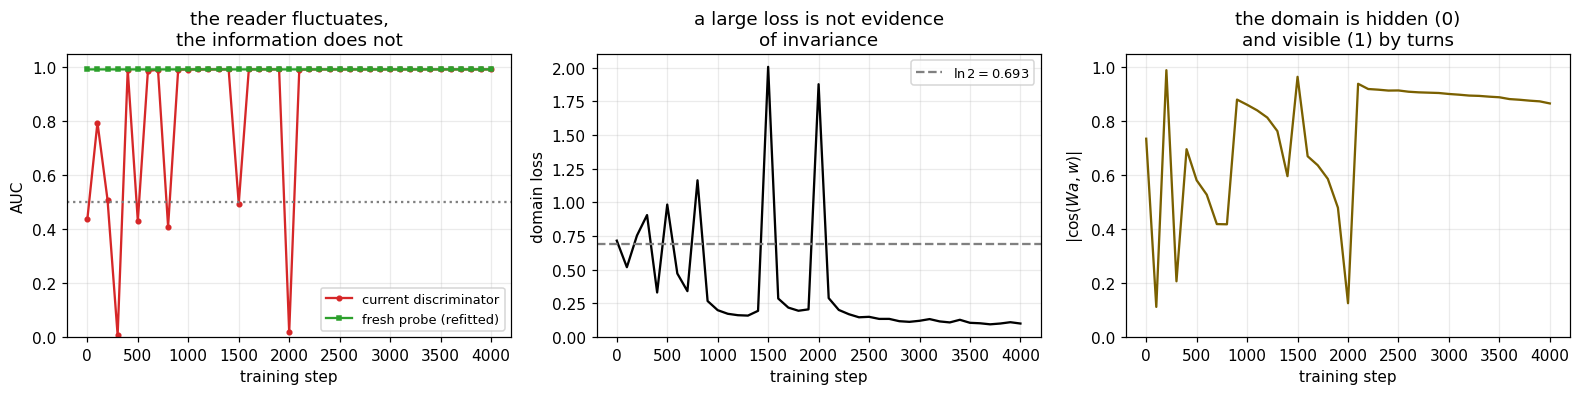

In [7]:
steps = [r["step"] for r in trace_a]
fig, axes = plt.subplots(1, 3, figsize=(14.5, 3.7))

axes[0].plot(steps, [r["auc_disc"] for r in trace_a], "o-", ms=3, color="#d62728",
             label="current discriminator")
axes[0].plot(steps, [r["auc_probe"] for r in trace_a], "s-", ms=3, color="#2ca02c",
             label="fresh probe (refitted)")
axes[0].axhline(0.5, ls=":", color="gray")
axes[0].set_xlabel("training step"); axes[0].set_ylabel("AUC"); axes[0].set_ylim(0, 1.05)
axes[0].legend(fontsize=8.5); axes[0].set_title("the reader fluctuates,\nthe information does not")

axes[1].plot(steps, [r["dom"] for r in trace_a], "-", color="black")
axes[1].axhline(np.log(2), ls="--", color="gray", label="$\\ln 2 = 0.693$")
axes[1].set_xlabel("training step"); axes[1].set_ylabel("domain loss")
axes[1].legend(fontsize=8.5); axes[1].set_title("a large loss is not evidence\nof invariance")

axes[2].plot(steps, [r["cos"] for r in trace_a], "-", color="#7a6000")
axes[2].set_ylim(0, 1.05); axes[2].set_xlabel("training step")
axes[2].set_ylabel("$|\\cos(Wa, w)|$")
axes[2].set_title("the domain is hidden (0)\nand visible (1) by turns")
plt.tight_layout(); plt.show()

### Reading the three panels

* **Left.** The fresh probe (green) sits at $0.99$ for the entire run: the domain is *always*
  fully present in the features. The current discriminator (red) swings between $\approx 1$ and
  $\approx 0$: sometimes it reads the domain perfectly, sometimes it is exactly wrong — but the
  information never left.
* **Middle.** The domain loss follows the same rhythm. Whenever the discriminator is confused,
  the loss is large (up to $\sim 2$). It would be easy, and completely wrong, to read that as
  "the domains have become indistinguishable". A large adversarial loss means only that *this*
  reader is currently wrong.
* **Right.** $|\cos(Wa, w)| = 0$ means the domain shift in feature space is orthogonal to the
  readout — hidden; $1$ means it lies right along it — in plain sight. The curve sweeps the whole
  range: the feature space **rotates**.

So in Case A the encoder does not remove anything. It rotates, the discriminator follows, and the
pair cycles. Note also the class accuracy — it stays at $0.99$ throughout, because a linear
classifier can absorb any invertible re-coordination of the features by simply re-pointing its
own weights.

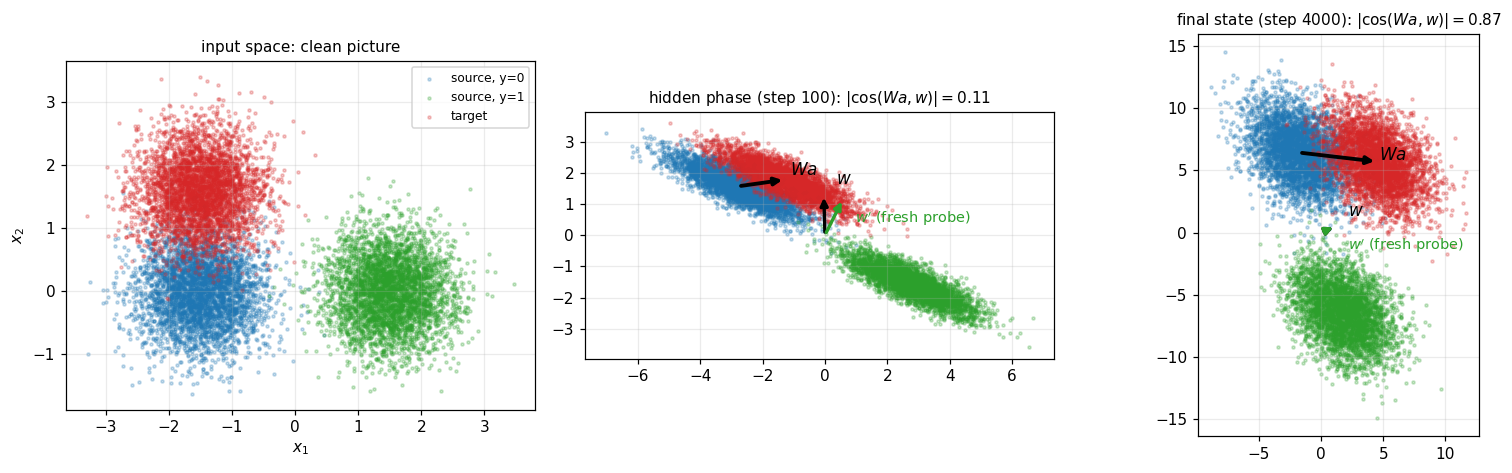

Hidden phase: the target cloud has been rotated onto the background cloud along the
direction the discriminator reads, so its readout loses the domain - while the fresh
probe finds it immediately (its own direction is not the stale one).


In [8]:
# Two phases of the same cycle, drawn: the most hidden moment and the final state.
k_blind = int(np.argmin([r["cos"] for r in trace_a]))
phases = [(trace_a[k_blind], f"hidden phase (step {trace_a[k_blind]['step']})"),
          (trace_a[-1], f"final state (step {trace_a[-1]['step']})")]

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.4))
ax = axes[0]
ax.scatter(s0[:, 0], s0[:, 1], s=4, alpha=0.25, color="#1f77b4", label="source, y=0")
ax.scatter(s1[:, 0], s1[:, 1], s=4, alpha=0.25, color="#2ca02c", label="source, y=1")
ax.scatter(tgt[:, 0], tgt[:, 1], s=4, alpha=0.25, color="#d62728", label="target")
ax.legend(fontsize=8, loc="upper right"); ax.set_aspect("equal")
ax.set_title("input space: clean picture", fontsize=10)
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")

for ax, (r, title) in zip(axes[1:], phases):
    enc = lambda X: X @ r["W"].T
    with torch.no_grad():
        Z0, Z1, Zt = enc(s0), enc(s1), enc(tgt)
    probe = LogisticRegression(max_iter=2000).fit(
        np.vstack([enc(torch.cat([h0, h1])).numpy(), enc(ht).numpy()]),
        np.r_[np.zeros(2 * N), np.ones(N)]).coef_[0]
    ax.scatter(Z0[:, 0], Z0[:, 1], s=4, alpha=0.25, color="#1f77b4")
    ax.scatter(Z1[:, 0], Z1[:, 1], s=4, alpha=0.25, color="#2ca02c")
    ax.scatter(Zt[:, 0], Zt[:, 1], s=4, alpha=0.25, color="#d62728")
    m_src, m_tgt = Z0.mean(0).numpy(), Zt.mean(0).numpy()
    ax.annotate("", xy=m_tgt, xytext=m_src,
                arrowprops=dict(arrowstyle="-|>", lw=2.5, color="black"))
    ax.text(*(m_tgt + 0.15), "$Wa$", fontsize=11)
    scale = 1.3 / max(float(r["w"].norm()), 1e-9)
    ax.annotate("", xy=r["w"].numpy() * scale, xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", lw=2.2, color="black"))
    ax.annotate("$w$", xy=r["w"].numpy() * scale, xytext=(8, 7),
                textcoords="offset points", fontsize=11)
    unit_probe = 1.3 * probe / np.linalg.norm(probe)
    ax.annotate("", xy=unit_probe, xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", lw=2.2, color="#2ca02c"))
    ax.annotate("$w'$ (fresh probe)", xy=unit_probe, xytext=(8, -16),
                textcoords="offset points", fontsize=9.5, color="#2ca02c")
    ax.set_aspect("equal")
    ax.set_title(f"{title}: $|\\cos(Wa,w)|={r['cos']:.2f}$", fontsize=10)
plt.tight_layout(); plt.show()

print("Hidden phase: the target cloud has been rotated onto the background cloud along the")
print("direction the discriminator reads, so its readout loses the domain - while the fresh")
print("probe finds it immediately (its own direction is not the stale one).")

## §6 Case B — a nonlinear encoder: a stably blind discriminator

Case A is a chase, and the chase is deceptive: a linear discriminator can always re-point and
recover, because a linear encoder can only rotate. Real encoders are not linear. Give the encoder
one hidden layer with a ReLU,

$$
z \;=\; W_2\,\mathrm{ReLU}(W_1 x + c_1) + c_2,
$$

and it gains something new: it can *fold* the feature space, i.e. re-encode the domain signal in
a form that no single linear readout can express, while leaving the class structure readable.

Everything else is unchanged: the same data, the same linear discriminator, the same losses, the
same $\lambda = 1$.

In [9]:
def train_case_b(steps=4000, lr=3e-3, batch=512, log_every=500, seed=0):
    torch.manual_seed(seed)
    encoder = nn.Sequential(nn.Linear(2, 16), nn.ReLU(), nn.Linear(16, 2))
    head = nn.Linear(2, 1)          # classifier v
    disc = nn.Linear(2, 1)          # discriminator w, b
    params = list(encoder.parameters()) + list(head.parameters()) + list(disc.parameters())
    opt = torch.optim.Adam(params, lr=lr)
    bce = nn.functional.binary_cross_entropy_with_logits
    trace = []

    for step in range(steps + 1):
        idx = torch.randint(0, N, (batch,))
        xs = torch.cat([s0[idx], s1[idx]])
        ys = torch.cat([torch.zeros(batch), torch.ones(batch)])
        xt = tgt[idx]

        zs, zt = encoder(xs), encoder(xt)
        cls = bce(head(zs).squeeze(), ys)
        dom = 0.5 * (bce(disc(Rev.apply(zs, 1.0)).squeeze(), torch.zeros(2 * batch))
                     + bce(disc(Rev.apply(zt, 1.0)).squeeze(), torch.ones(batch)))
        opt.zero_grad()
        (cls + dom).backward()
        opt.step()

        if step % log_every == 0:
            trace.append(dict(step=step, dom=float(dom.detach()),
                              auc_disc=discriminator_auc(encoder, disc),
                              auc_probe_lin=fresh_linear_probe_auc(encoder),
                              auc_probe_mlp=fresh_mlp_probe_auc(encoder),
                              acc=class_accuracy(encoder, head)))
    return encoder, head, disc, trace


enc_b, head_b, disc_b, trace_b = train_case_b()
print(f"{'step':>6}{'dom loss':>10}{'AUC discrim':>13}{'probe lin':>11}{'probe MLP':>11}"
      f"{'class acc':>11}")
for r in trace_b:
    print(f"{r['step']:>6}{r['dom']:>10.4f}{r['auc_disc']:>13.3f}{r['auc_probe_lin']:>11.3f}"
          f"{r['auc_probe_mlp']:>11.3f}{r['acc']:>11.3f}")

  step  dom loss  AUC discrim  probe lin  probe MLP  class acc
     0    0.7067        0.418      0.780      0.868      0.540
   500    0.7752        0.365      0.950      0.986      0.998
  1000    0.6926        0.539      0.549      0.985      0.998
  1500    0.6930        0.528      0.558      0.983      0.998
  2000    0.6958        0.491      0.523      0.982      0.999
  2500    0.6927        0.521      0.507      0.983      0.999
  3000    0.6973        0.511      0.528      0.981      0.999
  3500    0.6930        0.487      0.522      0.982      0.999
  4000    0.6939        0.487      0.521      0.984      0.999


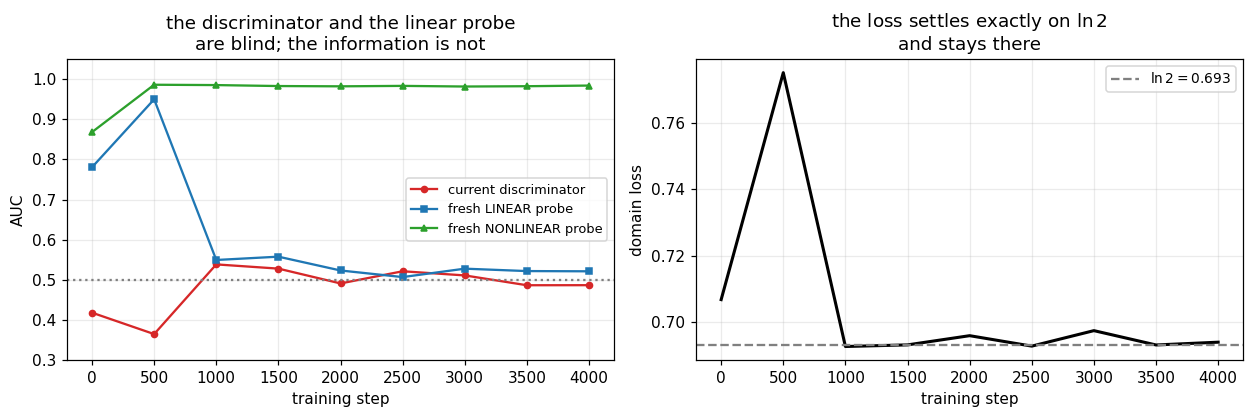

In [10]:
steps = [r["step"] for r in trace_b]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9))

axes[0].plot(steps, [r["auc_disc"] for r in trace_b], "o-", ms=4, color="#d62728",
             label="current discriminator")
axes[0].plot(steps, [r["auc_probe_lin"] for r in trace_b], "s-", ms=4, color="#1f77b4",
             label="fresh LINEAR probe")
axes[0].plot(steps, [r["auc_probe_mlp"] for r in trace_b], "^-", ms=4, color="#2ca02c",
             label="fresh NONLINEAR probe")
axes[0].axhline(0.5, ls=":", color="gray")
axes[0].set_ylim(0.3, 1.05); axes[0].set_xlabel("training step"); axes[0].set_ylabel("AUC")
axes[0].legend(fontsize=8.5, loc="center right")
axes[0].set_title("the discriminator and the linear probe\nare blind; the information is not")

axes[1].plot(steps, [r["dom"] for r in trace_b], "-", color="black", lw=2)
axes[1].axhline(np.log(2), ls="--", color="gray", label="$\\ln 2 = 0.693$")
axes[1].set_xlabel("training step"); axes[1].set_ylabel("domain loss")
axes[1].legend(fontsize=9)
axes[1].set_title("the loss settles exactly on $\\ln 2$\nand stays there")
plt.tight_layout(); plt.show()

### What happened in Case B

* The **domain loss** drops to $\ln 2 \approx 0.693$ and stays there — the value of a
  discriminator that has nothing to say. The **discriminator AUC** settles at $0.49$–$0.54$.
  Read alone, these two numbers would say "the domains have become indistinguishable".
* The **fresh linear probe** says the same thing: it falls from $0.95$ to $0.52$. A linear
  reader, refitted on the frozen features, cannot find the domain either.
* But the **fresh nonlinear probe** stays at $0.98$: the domain is fully present. It has been
  re-encoded into a nonlinear form — folded into the representation — so that no linear functional
  of $z$ can read it, while a reader with one hidden layer reads it instantly.
* The **class accuracy** stays at $0.999$. Hiding cost nothing.

This is the failure mode in its pure form: the meter that is the standard tool of the trade
(the domain loss, or a linear probe) reports success while the representation still carries the
domain in full.

## §7 The decisive test: freeze the encoder, refit the reader

How do we tell "the domain was removed" from "the reader is blind"? By taking the reader out of
the game. We freeze the encoder, and train a **new** reader on its frozen features:

* if the domain was removed, no reader can do better than chance — the features simply do not
  contain the information;
* if the domain was hidden, a sufficiently flexible reader recovers it immediately.

In the code above the encoder no longer changes, so this is a clean measurement of what the
representation holds. (In a real training loop the same test is implemented as a periodic
"discriminator refresh".)

In [11]:
for p in enc_b.parameters():
    p.requires_grad_(False)          # freeze the encoder for good


def refit_reader(kind="linear", steps=800, lr=1e-2, seed=0):
    # train a reader from scratch on the frozen features; return its domain AUC
    with torch.no_grad():
        Zs, Zt = enc_b(torch.cat([h0, h1])), enc_b(ht)
    y = np.r_[np.zeros(len(Zs)), np.ones(len(Zt))]
    X = np.vstack([Zs.numpy(), Zt.numpy()])
    if kind == "linear":
        clf = LogisticRegression(max_iter=2000).fit(X, y)
        return roc_auc_score(y, clf.predict_proba(X)[:, 1])

    torch.manual_seed(seed)
    net = nn.Sequential(nn.Linear(X.shape[1], 32), nn.ReLU(), nn.Linear(32, 1))
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    Xt = torch.tensor(X, dtype=torch.float32); yt = torch.tensor(y, dtype=torch.float32)
    for _ in range(steps):
        opt.zero_grad()
        nn.functional.binary_cross_entropy_with_logits(net(Xt).squeeze(), yt).backward()
        opt.step()
    with torch.no_grad():
        scores = torch.sigmoid(net(Xt).squeeze()).numpy()
    return roc_auc_score(y, scores)


print(f"refitted LINEAR reader    : domain AUC = {refit_reader('linear'):.3f}"
      "   <- no domain in the linear span of z")
print(f"refitted NONLINEAR reader : domain AUC = {refit_reader('mlp'):.3f}"
      "   <- the domain itself is intact")
print(f"class accuracy at the same features: {class_accuracy(enc_b, head_b):.3f}"
      "   <- and the class is unharmed")

refitted LINEAR reader    : domain AUC = 0.521   <- no domain in the linear span of z


refitted NONLINEAR reader : domain AUC = 0.984   <- the domain itself is intact
class accuracy at the same features: 0.999   <- and the class is unharmed


## §8 What to take away

**The mechanism, in one paragraph.** A discriminator is a function of the representation with a
scalar output, so the gradient it sends to the encoder lies along a single direction $w$
(§3). An encoder can therefore reduce the adversarial loss by re-coordinating the feature space —
rotating (Case A) or folding (Case B) the domain signal into directions the current reader does
not use — instead of by merging the two domains. Killing the class information is not required,
so the cheap option wins. The discriminator then adapts, and the game turns into a chase or
settles into a blind spot, depending on how much freedom the encoder has.

**Why the loss is not a certificate.** With an *exactly optimal* discriminator the value of the
game would be

$$
\text{value} \;=\; -\ln 4 \;+\; 2\,\mathrm{JSD}\big(p_{\text{src}}(z)\,\|\,p_{\text{tgt}}(z)\big),
$$

and the Jensen–Shannon divergence $\mathrm{JSD}$ is invariant under any invertible transformation
of the features (a change of variables cancels in the ratio of densities). With an optimal reader,
therefore, re-coordination buys *nothing*: the only way for the encoder to increase the loss is to
make the two feature distributions genuinely equal. The distance between this ideal and the actual
discriminator is exactly where hiding lives:

$$
\text{profit of hiding} \;=\; \text{value}(\text{current discriminator}) - \text{value}(\text{optimal}).
$$

This is why the practical fixes all aim at the same target — keep the reader close to optimal:
refit it periodically (§7), use several independent readers so that hiding from all of them at
once is much harder, or replace the adversarial objective with a non-adversarial one that cannot
be fooled.

**Checklist for real training.**

1. Never accept a small domain loss as evidence of invariance — it is equally consistent with a
   blind reader. Report the reader's own AUC *and* the fresh probe, side by side.
2. Refit the probe (and the discriminator) before believing any invariance claim.
3. Use a probe at least as expressive as the encoder's output can be: a linear probe
   underestimates how much domain information is present.
4. Always report the class metric next to the domain metric; invariance without class performance
   is worthless.

### Exercises

1. **Ensemble.** In Case A, train two discriminators with different random initialisations on the
   same features, and let the encoder maximise the *minimum* of the two losses (it must fool both).
   In a two-dimensional feature space two independent readout directions leave no blind
   direction at all. What happens to the class accuracy — what is the price of honest alignment?
2. **Entangled case.** Move the target domain along $e_1$ (the class axis) instead of $e_2$. Now
   hiding the domain without disturbing the class is impossible. Does the encoder sacrifice the
   class, and by how much?
3. **A slower reader.** In Case A, give the discriminator a learning rate ten times smaller (or
   update it only every tenth step). Look at how the depth of the swings in
   $|\cos(Wa,w)|$ changes. This models the "stale reader" regime of large real networks.
4. **Your own probe.** Replace the fresh linear probe with a $k$-nearest-neighbour classifier on
   the frozen features. Does it see the domain in Case B? Explain the difference from the linear
   probe — and where a distance-based meter could mislead you.